# Online Shoppers Intention: предсказание покупки в интернет-магазине

Предсказание того, закончится ли сессия посетителя покупкой (`Revenue`), по поведению в сессии и её контексту. Набор данных: Online Shoppers Purchasing Intention (12 330 сессий, 17 признаков, около 15% покупок).

**Что делаем:**
- заранее формулируем 7 проверяемых гипотез;
- разбираем данные: дисбаланс классов, коррелированные признаки, связь признаков с покупкой;
- собираем пайплайны так, чтобы никакая статистика не утекала из validation и test в обучение;
- сравниваем логистическую регрессию, решающее дерево и случайный лес, подбираем гиперпараметры кросс-валидацией;
- проверяем гипотезы отдельными экспериментами и по каждой пишем вывод с цифрами;
- выбираем порог классификации по out-of-fold предсказаниям и один раз оцениваем итоговую модель на тесте.

## 1. Гипотезы

Гипотезы сформулированы до обучения моделей. Для каждой заранее задан критерий, чтобы вердикт не зависел от того, что получилось.

1. **H1 (метрики).** Из-за дисбаланса классов accuracy вводит в заблуждение: у модели «всегда предсказывать 0» accuracy выше 0.80, а у лучшей настоящей модели accuracy превышает F1-macro больше чем на 0.10 (порог классификации 0.5).
2. **H2 (мультиколлинеарность).** Удаление сильно коррелированных числовых признаков (|r| > 0.8) не ухудшит логистическую регрессию: PR-AUC изменится по модулю меньше чем на 0.01.
3. **H3 (линейность).** Случайный лес обгонит логистическую регрессию по PR-AUC на тесте не меньше чем на 0.03, потому что в данных есть пороговые эффекты и взаимодействия, которых линейная модель не видит.
4. **H4 (важность признаков).** `PageValues` будет самым важным признаком дерева, а `ExitRates` и `ProductRelated_Duration` войдут в пятёрку самых важных.
5. **H5 (переобучение).** При глубине дерева больше 10 начнётся переобучение: train accuracy при глубине 20 превысит 0.97, а validation accuracy будет ниже своего максимума хотя бы на 0.02.
6. **H6 (баланс классов).** `class_weight='balanced'` сильно повысит recall покупок (не меньше чем на 0.20) ценой снижения precision.
7. **H7 (отбор признаков).** Отбор 10 лучших признаков через `SelectKBest` не ухудшит PR-AUC логистической регрессии больше чем на 0.02 относительно модели на всех признаках.

## 2. Импорты и настройки

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, average_precision_score, confusion_matrix, f1_score,
                             precision_recall_curve, precision_score, recall_score, roc_auc_score)
from sklearn.model_selection import (GridSearchCV, RandomizedSearchCV, RepeatedStratifiedKFold,
                                     StratifiedKFold, cross_val_predict, cross_val_score,
                                     cross_validate, train_test_split, validation_curve)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeClassifier

SEED = 42
TARGET = "Revenue"
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3})

## 3. Данные

Набор скачиваем с Kaggle через `kagglehub` (исходный источник: UCI Machine Learning Repository). Копия файла также лежит в `data/online_shoppers_intention.csv`.

Признаки:

- `Administrative`, `Informational`, `ProductRelated` — число просмотренных страниц каждого типа за сессию; `*_Duration` — время на страницах этого типа;
- `BounceRates`, `ExitRates` — средние доли отказов и выходов для страниц сессии (Google Analytics);
- `PageValues` — средняя «ценность» страниц, посещённых до покупки (Google Analytics);
- `SpecialDay` — близость даты сессии к особому дню (от 0 до 1);
- `Month`, `Weekend`, `VisitorType` — месяц, выходной, тип посетителя;
- `OperatingSystems`, `Browser`, `Region`, `TrafficType` — числовые идентификаторы, а не величины;
- `Revenue` — таргет: закончилась ли сессия покупкой.

In [ ]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("imakash3011/online-shoppers-purchasing-intention-dataset")

print("Path to dataset files:", path)

In [3]:
from pathlib import Path

csv_path = next(Path(path).glob("*.csv"))
data = pd.read_csv(csv_path)
print(f"Размер: {data.shape}")
data.head()

Размер: (12330, 18)


,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
0,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,1,1,1,1,Returning_Visitor,False,False
1,0,0.0,0,0.0,2,64.000000,0.00,0.10,0.0,0.0,Feb,2,2,1,2,Returning_Visitor,False,False
2,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,4,1,9,3,Returning_Visitor,False,False
3,0,0.0,0,0.0,2,2.666667,0.05,0.14,0.0,0.0,Feb,3,2,2,4,Returning_Visitor,False,False
4,0,0.0,0,0.0,10,627.500000,0.02,0.05,0.0,0.0,Feb,3,3,1,4,Returning_Visitor,True,False


## 4. Разведочный анализ

### 4.1 Пропуски, дубликаты, баланс классов

Пропусков (NaN): 0
Полных дубликатов строк: 125 (1.0%)
Доля покупок: 0.155


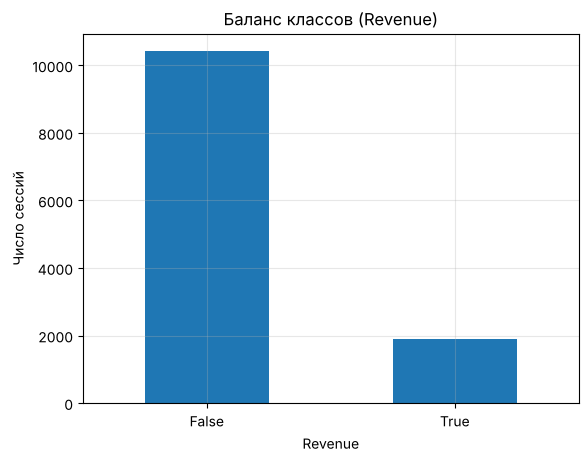

In [4]:
print(f"Пропусков (NaN): {data.isna().sum().sum()}")
print(f"Полных дубликатов строк: {data.duplicated().sum()} ({data.duplicated().mean():.1%})")
print(f"Доля покупок: {data[TARGET].mean():.3f}")

data[TARGET].value_counts().plot(kind="bar", rot=0, title="Баланс классов (Revenue)")
plt.ylabel("Число сессий")
plt.show()

Пропусков нет, поэтому импутер в пайплайн не добавляем. Покупкой заканчивается примерно каждая шестая сессия, то есть классы заметно несбалансированы: придётся делить выборку со стратификацией и аккуратно выбирать метрики. Дубликаты (около 1%) удалим до разбиения: если одна и та же строка попадёт и в train, и в test, оценка на тесте станет завышенной.

### 4.2 Распределения числовых признаков

Доля нулей в числовых признаках:
SpecialDay                 0.899
Informational_Duration     0.805
Informational              0.787
PageValues                 0.779
Administrative_Duration    0.479
Administrative             0.468
BounceRates                0.448
ProductRelated_Duration    0.061
ExitRates                  0.006
ProductRelated             0.003


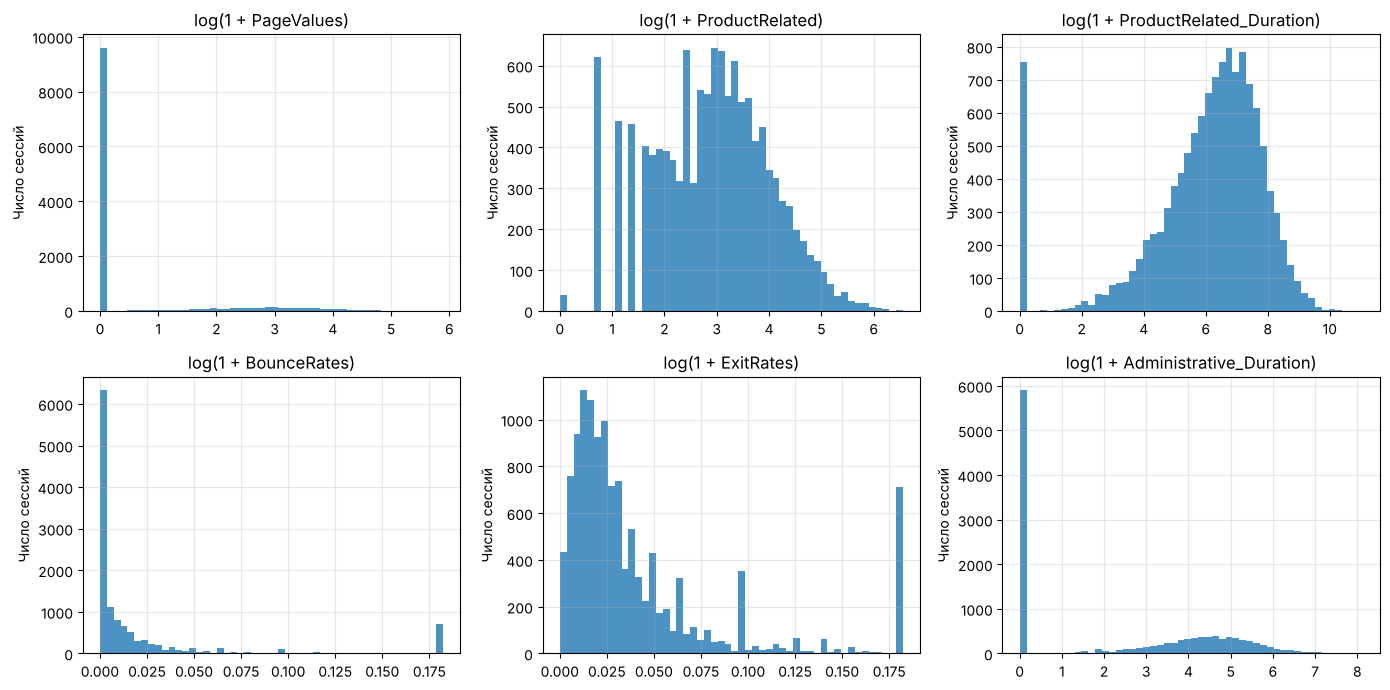

In [5]:
id_cols = ["OperatingSystems", "Browser", "Region", "TrafficType"]
num_eda = data.select_dtypes("number").columns.drop(id_cols).tolist()
zeros = (data[num_eda] == 0).mean().sort_values(ascending=False)
print("Доля нулей в числовых признаках:")
print(zeros.round(3).to_string())

fig, axes = plt.subplots(2, 3, figsize=(14, 7))
for ax, col in zip(axes.ravel(), ["PageValues", "ProductRelated", "ProductRelated_Duration",
                                  "BounceRates", "ExitRates", "Administrative_Duration"]):
    ax.hist(np.log1p(data[col]), bins=50, color="tab:blue", alpha=0.8)
    ax.set_title(f"log(1 + {col})")
    ax.set_ylabel("Число сессий")
plt.tight_layout()
plt.show()

Почти все признаки сильно скошены и содержат много нулей: у `SpecialDay`, `Informational`, `Informational_Duration` и `PageValues` нулевые значения составляют от 78% до 90% сессий. Для линейных моделей это повод стандартизовать признаки и проверить логарифм (`log1p`), деревьям это безразлично.

### 4.3 Корреляции

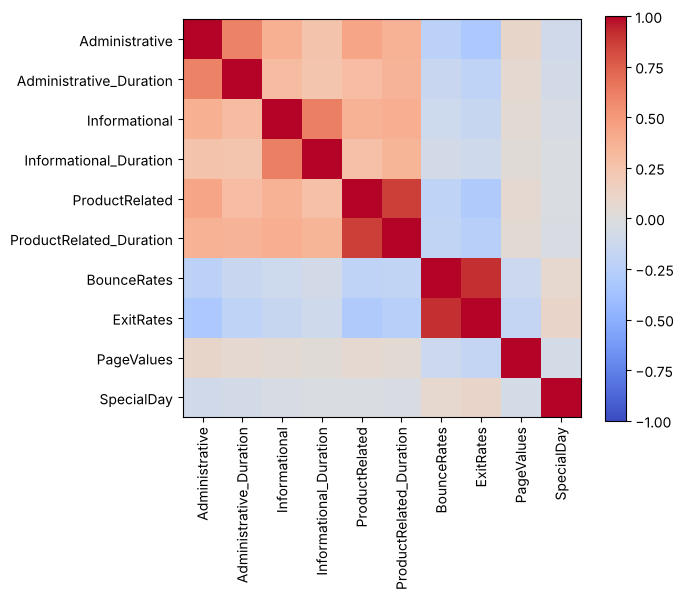

Пары признаков с |r| > 0.6:
BounceRates     ExitRates                  0.913
ProductRelated  ProductRelated_Duration    0.861
Informational   Informational_Duration     0.619
Administrative  Administrative_Duration    0.602


In [6]:
corr = data[num_eda].corr()
fig, ax = plt.subplots(figsize=(7, 6))
im = ax.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(range(len(num_eda)), num_eda, rotation=90)
ax.set_yticks(range(len(num_eda)), num_eda)
ax.grid(False)
plt.colorbar(im)
plt.tight_layout()
plt.show()

pairs = corr.where(np.triu(np.ones(corr.shape, dtype=bool), 1)).stack()
print("Пары признаков с |r| > 0.6:")
print(pairs[pairs.abs() > 0.6].sort_values(ascending=False).round(3).to_string())

Сильно коррелированы две пары: `BounceRates` и `ExitRates` (0.91) и `ProductRelated` и `ProductRelated_Duration` (0.86): чем больше страниц, тем больше времени на них. Пары `Administrative`/`Administrative_Duration` и `Informational`/`Informational_Duration` связаны слабее (около 0.6). Это материал для гипотезы H2.

### 4.4 Связь признаков с покупкой

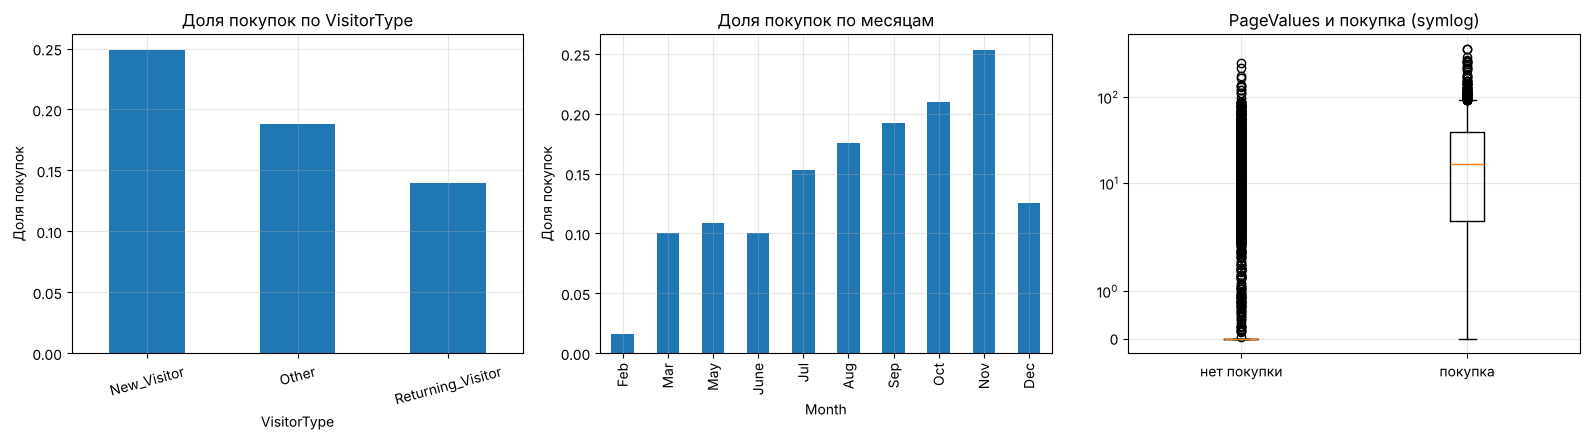

Доля покупок при PageValues == 0: 0.039
Доля покупок при PageValues  > 0: 0.563
Среди покупателей PageValues > 0 у 80.6%


In [7]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
data.groupby("VisitorType")[TARGET].mean().plot(kind="bar", rot=15, ax=axes[0], title="Доля покупок по VisitorType")
month_order = ["Feb", "Mar", "May", "June", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
data.groupby("Month")[TARGET].mean().reindex(month_order).plot(kind="bar", ax=axes[1], title="Доля покупок по месяцам")
axes[2].boxplot([data.loc[data[TARGET] == 0, "PageValues"], data.loc[data[TARGET] == 1, "PageValues"]],
                tick_labels=["нет покупки", "покупка"])
axes[2].set_yscale("symlog")
axes[2].set_title("PageValues и покупка (symlog)")
for ax in axes[:2]:
    ax.set_ylabel("Доля покупок")
plt.tight_layout()
plt.show()

has_pv = data["PageValues"] > 0
print(f"Доля покупок при PageValues == 0: {data.loc[~has_pv, TARGET].mean():.3f}")
print(f"Доля покупок при PageValues  > 0: {data.loc[has_pv, TARGET].mean():.3f}")
print(f"Среди покупателей PageValues > 0 у {has_pv[data[TARGET] == 1].mean():.1%}")

**Наблюдения:**

- `PageValues` — самый сильный сигнал. У 77.9% сессий он равен нулю, и в таких сессиях покупок всего 3.9%; при `PageValues > 0` покупка происходит в 56.3% сессий, а у 80.6% покупателей признак ненулевой.
- Новые посетители покупают заметно чаще вернувшихся (24.9% против 13.9%), хотя сессий вернувшихся в 6 раз больше (10 551 против 1 694). Категория `Other` слишком мала (85 сессий) для выводов.
- Сезонность выражена: в ноябре покупок 25.4% (2 998 сессий), в феврале всего 1.6% (184 сессии). В данных только 10 месяцев, января и апреля нет.
- В выходные покупают чуть чаще (17.4% против 14.9%), рядом с особыми днями (`SpecialDay > 0`) покупок меньше (3.4–8.3% против 16.5% в обычные дни).
- Осторожность: `PageValues` считается по страницам, после которых случались покупки, поэтому признак может частично «знать» исход сессии. Ниже проверим, насколько модели от него зависят (раздел 9).

## 5. Подготовка и разбиение данных

Порядок выбран так, чтобы не было утечек:

1. удаляем дубликаты **до** разбиения;
2. делим выборку на train и test со стратификацией, **до** любого обучения и подбора параметров;
3. все преобразования (стандартизация, `log1p`, one-hot, отбор признаков) оформляем как шаги `Pipeline`, чтобы на каждом фолде кросс-валидации они обучались только на обучающей части фолда; список коррелированных признаков для H2 определяем только по train и без таргета;
4. тест используем только в самом конце, для оценки уже выбранных моделей.

`OperatingSystems`, `Browser`, `Region` и `TrafficType` — это идентификаторы: «браузер 8» не больше «браузера 2». Поэтому трактуем их как категории и кодируем one-hot.

In [8]:
data = data.drop_duplicates().reset_index(drop=True)
data[TARGET] = data[TARGET].astype(int)
data["Weekend"] = data["Weekend"].astype(int)
data[id_cols] = data[id_cols].astype(str)

X = data.drop(columns=TARGET)
y = data[TARGET]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=SEED, stratify=y)

cat_cols = ["Month", "VisitorType"] + id_cols
num_cols = [c for c in X.columns if c not in cat_cols]
print(f"После удаления дубликатов: {len(data)} сессий")
print(f"Train: {X_train.shape}, Test: {X_test.shape}")
print(f"Доля покупок в train / test: {y_train.mean():.3f} / {y_test.mean():.3f}")
print(f"Покупок в test: {y_test.sum()}, одна ошибка меняет recall на {1 / y_test.sum():.2%}")
print(f"Числовых признаков: {len(num_cols)}, категориальных: {len(cat_cols)}")

После удаления дубликатов: 12205 сессий
Train: (9764, 17), Test: (2441, 17)
Доля покупок в train / test: 0.156 / 0.156
Покупок в test: 382, одна ошибка меняет recall на 0.26%
Числовых признаков: 11, категориальных: 6


### Препроцессор

Числовые признаки стандартизуем (`StandardScaler`), а скошенные дополнительно прогоняем через `log1p` (`FunctionTransformer`) — это включается флагом. Категориальные кодируем `OneHotEncoder`. Всё собрано в `ColumnTransformer`, который стоит первым шагом каждого `Pipeline`.

In [9]:
SKEWED = ["Administrative", "Administrative_Duration", "Informational", "Informational_Duration",
          "ProductRelated", "ProductRelated_Duration", "PageValues"]


def make_preprocessor(num=None, use_cat=True, log_skewed=False):
    num = list(num_cols if num is None else num)
    skewed = [c for c in num if c in SKEWED] if log_skewed else []
    rest = [c for c in num if c not in skewed]
    transformers = []
    if skewed:
        log_scale = Pipeline([("log", FunctionTransformer(np.log1p, feature_names_out="one-to-one")),
                              ("scale", StandardScaler())])
        transformers.append(("num_log", log_scale, skewed))
    if rest:
        transformers.append(("num", StandardScaler(), rest))
    if use_cat:
        transformers.append(("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat_cols))
    return ColumnTransformer(transformers)

## 6. Метрики

Положительный класс — покупка (`Revenue = 1`): именно её мы хотим находить. Из-за дисбаланса accuracy плохо различает модели: «всегда предсказывать 0» даёт accuracy около 0.84. Поэтому смотрим на:

- **PR-AUC** (`average_precision`) — основная метрика, по ней подбираем гиперпараметры. Она не зависит от порога и чувствительна к качеству именно на редком классе; у случайного ранжирования она равна доле покупок (≈ 0.16);
- **ROC-AUC** — вторая метрика ранжирования, менее чувствительная к дисбалансу;
- **F1** по классу покупок $F_1 = \frac{2PR}{P + R}$ и **F1-macro** — качество жёстких предсказаний при пороге 0.5;
- **accuracy** — только для сравнения с F1-macro (гипотеза H1).

Кросс-валидация — 5-fold со стратификацией, на **train**. Для каждой конфигурации сохраняем среднее по фолдам и стандартное отклонение PR-AUC, чтобы отличать реальные различия от шума.

In [10]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
scoring = {"PR-AUC": "average_precision", "ROC-AUC": "roc_auc", "F1": "f1",
           "F1-macro": "f1_macro", "accuracy": "accuracy"}
results = []


def evaluate(name, model, X=None):
    """CV-метрики на train: добавляет строку в results."""
    X = X_train if X is None else X
    res = cross_validate(model, X, y_train, cv=cv, scoring=scoring, n_jobs=-1)
    row = {"model": name}
    row.update({k: res[f"test_{k}"].mean() for k in scoring})
    row["PR-AUC std"] = res["test_PR-AUC"].std()
    results.append(row)
    return row

## 7. Бейзлайны и первые улучшения (проверка H1)

Начинаем с тривиального классификатора и постепенно усложняем: логистическая регрессия только на числовых признаках, затем с категориями, затем с логарифмом скошенных признаков. Деревья и лес — с параметрами по умолчанию.

In [11]:
def pipe(clf, **prep_kw):
    return Pipeline([("prep", make_preprocessor(**prep_kw)), ("clf", clf)])


evaluate("Dummy (всегда 0)", pipe(DummyClassifier(strategy="most_frequent")))
evaluate("LogReg, числовые признаки", pipe(LogisticRegression(max_iter=3000), use_cat=False))
evaluate("LogReg + категории (one-hot)", pipe(LogisticRegression(max_iter=3000)))
evaluate("LogReg + категории + log1p", pipe(LogisticRegression(max_iter=3000), log_skewed=True))
evaluate("DecisionTree (по умолчанию)", pipe(DecisionTreeClassifier(random_state=SEED)))
evaluate("RandomForest (по умолчанию)", pipe(RandomForestClassifier(n_estimators=200, random_state=SEED)))
pd.DataFrame(results).set_index("model").round(4)

,PR-AUC,ROC-AUC,F1,F1-macro,accuracy,PR-AUC std
model,,,,,,
Dummy (всегда 0),0.1563,0.5000,0.0000,0.4576,0.8437,0.0002
"LogReg, числовые признаки",0.6351,0.8794,0.4877,0.7102,0.8811,0.0182
LogReg + категории (one-hot),0.6353,0.8883,0.4953,0.7141,0.8817,0.0221
LogReg + категории + log1p,0.6829,0.9116,0.6168,0.7775,0.8935,0.0207
DecisionTree (по умолчанию),0.3810,0.7409,0.5594,0.7381,0.8601,0.0180
RandomForest (по умолчанию),0.7404,0.9234,0.6194,0.7810,0.9002,0.0186


In [12]:
no_log = cross_val_score(pipe(LogisticRegression(max_iter=3000)), X_train, y_train, cv=cv, scoring="average_precision")
with_log = cross_val_score(pipe(LogisticRegression(max_iter=3000), log_skewed=True), X_train, y_train, cv=cv, scoring="average_precision")
print("Прирост PR-AUC от log1p по фолдам:", (with_log - no_log).round(3))
print(f"Среднее {np.mean(with_log - no_log):+.4f}, std разностей {np.std(with_log - no_log):.4f}")

Прирост PR-AUC от log1p по фолдам: [0.024 0.053 0.066 0.057 0.037]
Среднее +0.0476, std разностей 0.0150


**Выводы по бейзлайнам:**

- Dummy уже даёт accuracy 0.844, а настоящие модели — 0.86–0.90. Зато PR-AUC у Dummy равен доле покупок (0.156), а у лучшего бейзлайна (лес по умолчанию) 0.740. Это и есть причина, по которой основной метрикой выбран PR-AUC, а не accuracy.
- Категориальные признаки линейной модели почти ничего не дают: PR-AUC 0.6351 → 0.6353 при std по фолдам около 0.02, ROC-AUC 0.879 → 0.888. Оставляем их в пайплайне: они ничего не портят.
- **`log1p` заметно помогает логистической регрессии:** PR-AUC 0.635 → 0.683, F1 по покупкам 0.495 → 0.617, ROC-AUC 0.888 → 0.912. Прирост положительный на всех пяти фолдах (от +0.024 до +0.066, среднее +0.048 при std разностей 0.015), поэтому это не шум. Причина: признаки скошены, с большой массой нулей и тяжёлыми хвостами, и на сырой шкале несколько огромных значений определяют веса модели. Дальше везде используем `log1p` для скошенных признаков (для деревьев он ничего не меняет).
- Одиночное дерево с параметрами по умолчанию сильно переобучено: PR-AUC 0.381, хуже логистической регрессии, ROC-AUC всего 0.741. Лес из таких же деревьев без подбора параметров сразу лучший (PR-AUC 0.740): усреднение гасит их нестабильность.

In [13]:
base = pd.DataFrame(results).set_index("model")
dummy = base.loc["Dummy (всегда 0)"]
best = base.drop("Dummy (всегда 0)")["PR-AUC"].idxmax()
gap = base.loc[best, "accuracy"] - base.loc[best, "F1-macro"]
print(f"Dummy: accuracy = {dummy['accuracy']:.3f}")
print(f"Лучшая по PR-AUC: {best}: accuracy = {base.loc[best, 'accuracy']:.3f}, "
      f"F1-macro = {base.loc[best, 'F1-macro']:.3f}, разность = {gap:.3f}")
print(f"H1 выполнена: {dummy['accuracy'] > 0.80 and gap > 0.10}")

Dummy: accuracy = 0.844
Лучшая по PR-AUC: RandomForest (по умолчанию): accuracy = 0.900, F1-macro = 0.781, разность = 0.119
H1 выполнена: True


**Выводы по H1: подтвердилась.**

- У Dummy accuracy 0.844, у лучшей по PR-AUC базовой модели (лес по умолчанию) 0.900: настоящая модель выигрывает всего 5.6 п. п. F1-macro этой модели 0.781, то есть accuracy выше на 0.119 (порог 0.10).
- Критерий проходит с небольшим запасом. У подобранного леса на тесте (раздел 8) разность accuracy и F1-macro равна 0.9070 − 0.8109 = 0.096, то есть уже чуть ниже порога. Суть гипотезы (accuracy завышает качество) верна, но число 0.10 стоит читать как ориентир, а не как жёсткий порог.
- Яснее всего различие видно на метриках редкого класса: PR-AUC 0.156 у Dummy против 0.740 у леса, F1 по покупкам 0 против 0.619. Поэтому дальше ориентируемся на PR-AUC и F1.

## 8. Подбор гиперпараметров

Подбираем параметры кросс-валидацией **на train** по PR-AUC: сетка для логистической регрессии (`GridSearchCV`), случайный поиск для дерева и леса (`RandomizedSearchCV`). Препроцессор берём из лучшего варианта бейзлайна для линейной модели.

In [14]:
USE_LOG = True
PREP = dict(log_skewed=USE_LOG)
print(f"log1p для скошенных признаков: {USE_LOG}")

searches = {
    "LogReg": GridSearchCV(
        pipe(LogisticRegression(max_iter=5000), **PREP),
        {"clf__C": [0.001, 0.01, 0.1, 1, 10, 100]},
        cv=cv, scoring="average_precision", n_jobs=-1),
    "DecisionTree": RandomizedSearchCV(
        pipe(DecisionTreeClassifier(random_state=SEED), **PREP),
        {"clf__max_depth": list(range(2, 16)), "clf__min_samples_leaf": [1, 5, 10, 20, 50],
         "clf__criterion": ["gini", "entropy"]},
        n_iter=30, cv=cv, scoring="average_precision", n_jobs=-1, random_state=SEED),
    "RandomForest": RandomizedSearchCV(
        pipe(RandomForestClassifier(random_state=SEED), **PREP),
        {"clf__n_estimators": [200, 400], "clf__max_depth": [5, 8, 12, None],
         "clf__min_samples_leaf": [1, 3, 5, 10], "clf__max_features": ["sqrt", 0.3]},
        n_iter=12, cv=cv, scoring="average_precision", n_jobs=-1, random_state=SEED),
}

tuned = {}
for name, search in searches.items():
    search.fit(X_train, y_train)
    tuned[name] = search.best_estimator_
    print(f"{name}: CV PR-AUC = {search.best_score_:.4f}, параметры: {search.best_params_}")

log1p для скошенных признаков: True


LogReg: CV PR-AUC = 0.6848, параметры: {'clf__C': 0.1}


DecisionTree: CV PR-AUC = 0.7129, параметры: {'clf__min_samples_leaf': 50, 'clf__max_depth': 15, 'clf__criterion': 'gini'}


RandomForest: CV PR-AUC = 0.7563, параметры: {'clf__n_estimators': 400, 'clf__min_samples_leaf': 1, 'clf__max_features': 0.3, 'clf__max_depth': 8}


**Что выбрал подбор:**

- **LogReg:** `C = 0.1`, CV PR-AUC 0.6848. Относительно `C = 1` по умолчанию (0.6829) почти ничего не изменилось.
- **DecisionTree:** `min_samples_leaf = 50`, `max_depth = 15`, CV PR-AUC 0.7129 (против 0.381 у дерева по умолчанию). Это намекает, что важнее не глубина, а минимальный размер листа: глубокое дерево допустимо, пока в каждом листе не меньше 50 объектов (к этому вернёмся в разделе 10).
- **RandomForest:** 400 деревьев, `max_depth = 8`, `max_features = 0.3`, `min_samples_leaf = 1`, CV PR-AUC 0.7563.

Лес выигрывает у обеих моделей больше чем на 0.04 (std по фолдам около 0.02, судя по бейзлайнам), а различие между деревом и логистической регрессией (0.713 и 0.685) одного порядка с шумом.

### Оценка на тесте

Теперь один раз оцениваем выбранные модели на тесте (порог 0.5). Решений по этим цифрам не принимаем, кроме проверки H3.

,PR-AUC,ROC-AUC,precision,recall,F1,F1-macro,accuracy
model,,,,,,,
LogReg,0.6968,0.9224,0.7179,0.5995,0.6534,0.7976,0.9005
DecisionTree,0.7004,0.9157,0.7197,0.5916,0.6494,0.7956,0.9000
RandomForest,0.7601,0.9362,0.7429,0.6204,0.6762,0.8109,0.9070


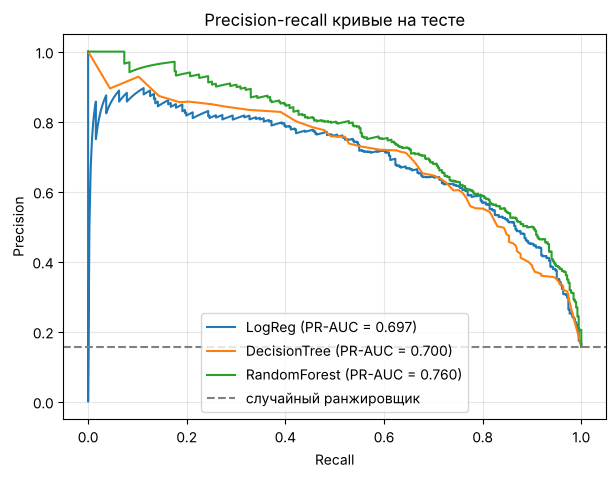

PR-AUC(RF) - PR-AUC(LogReg) = 0.0633
H3 выполнена: True


In [15]:
def test_metrics(name, model):
    proba = model.predict_proba(X_test)[:, 1]
    pred = (proba >= 0.5).astype(int)
    return {"model": name, "PR-AUC": average_precision_score(y_test, proba), "ROC-AUC": roc_auc_score(y_test, proba),
            "precision": precision_score(y_test, pred), "recall": recall_score(y_test, pred),
            "F1": f1_score(y_test, pred), "F1-macro": f1_score(y_test, pred, average="macro"),
            "accuracy": accuracy_score(y_test, pred)}


test_table = pd.DataFrame([test_metrics(n, m) for n, m in tuned.items()]).set_index("model")
display(test_table.round(4))

fig, ax = plt.subplots(figsize=(7, 5))
for name, model in tuned.items():
    p, r, _ = precision_recall_curve(y_test, model.predict_proba(X_test)[:, 1])
    ax.plot(r, p, label=f"{name} (PR-AUC = {test_table.loc[name, 'PR-AUC']:.3f})")
ax.axhline(y_test.mean(), color="gray", linestyle="--", label="случайный ранжировщик")
ax.set_xlabel("Recall")
ax.set_ylabel("Precision")
ax.set_title("Precision-recall кривые на тесте")
ax.legend()
plt.show()

diff = test_table.loc["RandomForest", "PR-AUC"] - test_table.loc["LogReg", "PR-AUC"]
print(f"PR-AUC(RF) - PR-AUC(LogReg) = {diff:.4f}")
print(f"H3 выполнена: {diff >= 0.03}")

**Выводы по H3: подтвердилась.**

- На тесте PR-AUC леса 0.760, логистической регрессии 0.697: разница 0.063 при пороге 0.03. Кросс-валидация показывает тот же знак и сопоставимую величину (0.756 против 0.685, разница 0.072), так что результат не случайность одного разбиения.
- Подобранное одиночное дерево (0.700 на тесте) почти не отличается от логистической регрессии (0.697): само по себе дерево нелинейно, но не лучше линейной модели. Выигрыш леса — это в первую очередь усреднение нестабильных деревьев, а не «нелинейность вообще».
- Feature engineering сократил разрыв между линейной моделью и лесом: без `log1p` логистическая регрессия давала на CV PR-AUC 0.635, с ним 0.683, а лес по умолчанию — 0.740. Если бы мы оставили сырую шкалу, вывод «лес намного лучше» оказался бы сильнее, чем он есть на самом деле.
- В тесте всего 382 покупки, поэтому отдельные значения метрик шумят. Но эти различия стабильно воспроизводятся и в CV.

## 9. Важность признаков (проверка H4)

Смотрим два способа: важность по уменьшению неопределённости (`feature_importances_`) для подобранного дерева (по one-hot-столбцам) и permutation importance по исходным признакам. Второй способ не размазывает важность категориального признака по его one-hot-столбцам. Это интерпретация уже выбранной модели, никакие решения по ней не принимаются.

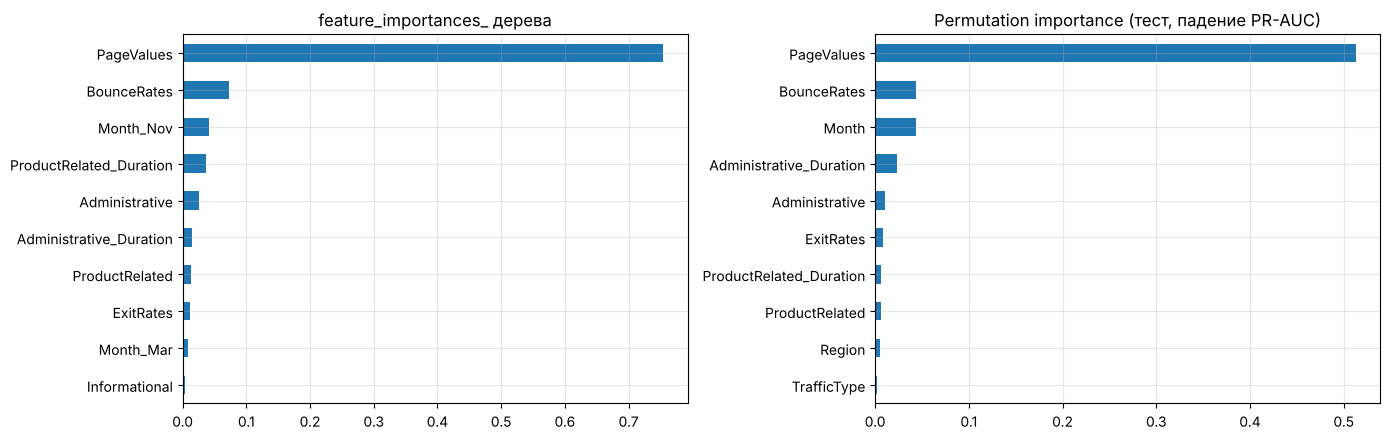

Топ-5 по feature_importances_: {'PageValues': 0.755, 'BounceRates': 0.072, 'Month_Nov': 0.042, 'ProductRelated_Duration': 0.037, 'Administrative': 0.026}
Топ-5 по permutation importance: {'PageValues': 0.5131, 'BounceRates': 0.0438, 'Month': 0.0435, 'Administrative_Duration': 0.0235, 'Administrative': 0.0102}
ExitRates: место по feature_importances_ = 8, по permutation importance = 6
ProductRelated_Duration: место по feature_importances_ = 4, по permutation importance = 7
H4 выполнена: False


In [16]:
tree = tuned["DecisionTree"]
names = [n.split("__", 1)[1] for n in tree.named_steps["prep"].get_feature_names_out()]
imp = pd.Series(tree.named_steps["clf"].feature_importances_, index=names).sort_values(ascending=False)

pi = permutation_importance(tree, X_test, y_test, scoring="average_precision",
                            n_repeats=10, random_state=SEED, n_jobs=-1)
perm = pd.Series(pi.importances_mean, index=X_test.columns).sort_values(ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
imp.head(10).iloc[::-1].plot(kind="barh", ax=axes[0], title="feature_importances_ дерева")
perm.head(10).iloc[::-1].plot(kind="barh", ax=axes[1], title="Permutation importance (тест, падение PR-AUC)")
plt.tight_layout()
plt.show()

print("Топ-5 по feature_importances_:", {n: round(v, 3) for n, v in imp.head(5).items()})
print("Топ-5 по permutation importance:", perm.head(5).round(4).to_dict())
for col in ["ExitRates", "ProductRelated_Duration"]:
    print(f"{col}: место по feature_importances_ = {list(imp.index).index(col) + 1}, "
          f"по permutation importance = {list(perm.index).index(col) + 1}")
top5 = set(imp.index[:5])
print(f"H4 выполнена: {imp.index[0] == 'PageValues' and {'ExitRates', 'ProductRelated_Duration'} <= top5}")

**Выводы по H4: частично подтвердилась.**

- Первая часть подтвердилась с огромным запасом: `PageValues` — признак №1 по обоим методам. По `feature_importances_` на него приходится 75.5% всей важности (у следующего, `BounceRates`, 7.2%), а перестановка `PageValues` на тесте снижает PR-AUC дерева на 0.51 (у `BounceRates` и `Month` около 0.04).
- Вторая часть не подтвердилась: `ExitRates` на 8-м месте по `feature_importances_` и на 6-м по permutation importance. `ProductRelated_Duration` на 4-м месте по `feature_importances_`, но на 7-м по permutation importance, то есть в пятёрку попадает только по одному из двух методов.
- `ExitRates` ниже `BounceRates` не потому, что бесполезен: эти признаки коррелируют (r ≈ 0.9), дерево при выборе разбиения чаще берёт один из них, а второй получает остаток важности. Это согласуется с H2 (корреляционный фильтр убрал `ExitRates` без потери качества).
- Общие признаки обоих топ-5: `PageValues`, `BounceRates`, `Administrative` и `Month`; расходятся `ProductRelated_Duration` и `Administrative_Duration`. Это типичное «размазывание» важности по коррелированным признакам и по one-hot-столбцам, поэтому порядок после первого места стоит читать осторожно.

### Что если убрать `PageValues`?

`PageValues` считается в Google Analytics по страницам, после которых совершались покупки. Значит, признак может частично «знать» исход сессии, и в реальном применении надо проверять, доступен ли он к моменту предсказания. Оценим, насколько модели от него зависят: повторим кросс-валидацию лучших моделей без этого признака.

In [17]:
num_no_pv = [c for c in num_cols if c != "PageValues"]
X_train_no_pv = X_train.drop(columns="PageValues")
rows = []
for name, model in tuned.items():
    m = clone(model).set_params(prep=make_preprocessor(num=num_no_pv, **PREP))
    scores = cross_val_score(m, X_train_no_pv, y_train, cv=cv, scoring="average_precision", n_jobs=-1)
    with_pv = cross_val_score(model, X_train, y_train, cv=cv, scoring="average_precision", n_jobs=-1)
    rows.append({"model": name, "PR-AUC с PageValues": with_pv.mean(),
                 "PR-AUC без PageValues": scores.mean(), "std без": scores.std()})
pd.DataFrame(rows).set_index("model").round(4)

,PR-AUC с PageValues,PR-AUC без PageValues,std без
model,,,
LogReg,0.6848,0.3422,0.0316
DecisionTree,0.7129,0.3209,0.0072
RandomForest,0.7563,0.3830,0.0264


**Выводы:**

- Без `PageValues` качество падает больше чем вдвое: PR-AUC логистической регрессии 0.685 → 0.342, дерева 0.713 → 0.321, леса 0.756 → 0.383. Все три модели теряют 0.3–0.4, то есть почти всё предсказательное качество держится на одном признаке. Без него лучшая модель всё ещё заметно лучше случайной (0.156), поэтому поведение в сессии сигнал несёт, но слабый.
- Различия между моделями без `PageValues` сопоставимы с шумом (std по фолдам до 0.03): лес по-прежнему впереди, но логистическую регрессию (0.342) и дерево (0.321) разделять уже нельзя.
- Что это значит: цифры с `PageValues` нужно читать осторожно. Признак считается по историческим покупкам, и если в реальной системе он недоступен до конца сессии или включает исход самой сессии, то реальное качество будет ближе к столбцу «без PageValues». Доказанной утечкой мы это назвать не можем (способ расчёта нам не известен), но это конкретный риск, который стоит проверять первым.

## 10. Переобучение дерева по глубине (проверка H5)

Строим кривые по `max_depth` от 1 до 20 кросс-валидацией на train: средние train и validation по фолдам. Тест не используется.

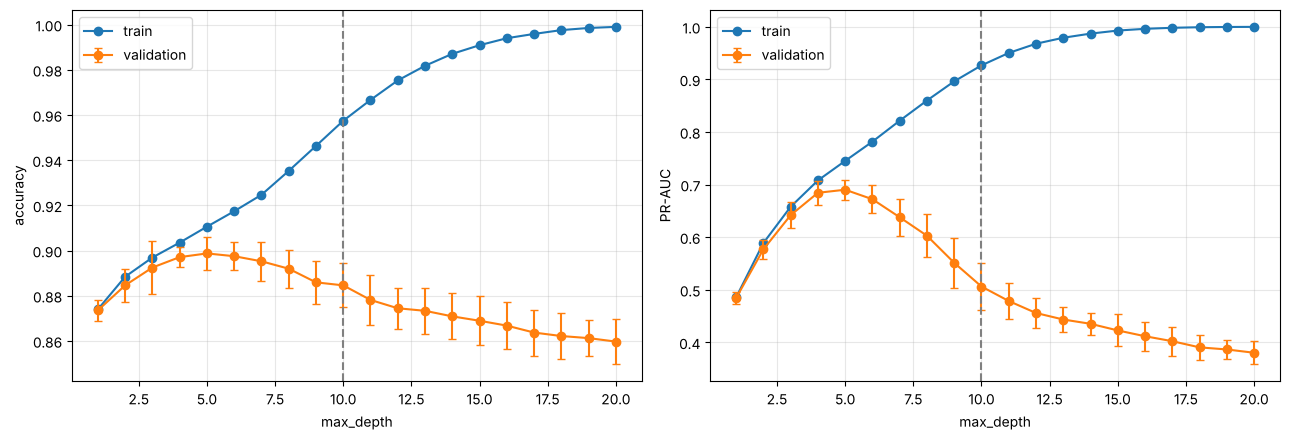

Лучшая глубина по validation accuracy: 5 (accuracy = 0.8987)
Глубина 20: train = 0.9990, validation = 0.8597
Глубина 5 / 10 / 20, validation accuracy: 0.8987 / 0.8846 / 0.8597; train accuracy: 0.9105 / 0.9574 / 0.9990
Лучшая глубина по validation PR-AUC: 5 (PR-AUC = 0.6901)
Глубина 5 / 10 / 20, validation PR-AUC: 0.6901 / 0.5061 / 0.3801
H5 выполнена: True


In [18]:
depths = list(range(1, 21))
tree_pipe = pipe(DecisionTreeClassifier(random_state=SEED), **PREP)
curves = {}
for metric in ["accuracy", "average_precision"]:
    tr, va = validation_curve(tree_pipe, X_train, y_train, param_name="clf__max_depth",
                              param_range=depths, cv=cv, scoring=metric, n_jobs=-1)
    curves[metric] = (tr.mean(axis=1), va.mean(axis=1), va.std(axis=1))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for ax, (metric, (tr, va, va_std)), label in zip(axes, curves.items(), ["accuracy", "PR-AUC"]):
    ax.plot(depths, tr, marker="o", label="train")
    ax.errorbar(depths, va, yerr=va_std, marker="o", capsize=3, label="validation")
    ax.axvline(10, color="gray", linestyle="--")
    ax.set_xlabel("max_depth")
    ax.set_ylabel(label)
    ax.legend()
plt.tight_layout()
plt.show()

tr_acc, va_acc, _ = curves["accuracy"]
print(f"Лучшая глубина по validation accuracy: {depths[int(va_acc.argmax())]} (accuracy = {va_acc.max():.4f})")
print(f"Глубина 20: train = {tr_acc[-1]:.4f}, validation = {va_acc[-1]:.4f}")
tr_pr, va_pr, _ = curves["average_precision"]
print(f"Глубина 5 / 10 / 20, validation accuracy: {va_acc[4]:.4f} / {va_acc[9]:.4f} / {va_acc[19]:.4f}; train accuracy: "
      f"{tr_acc[4]:.4f} / {tr_acc[9]:.4f} / {tr_acc[19]:.4f}")
print(f"Лучшая глубина по validation PR-AUC: {depths[int(va_pr.argmax())]} (PR-AUC = {va_pr.max():.4f})")
print(f"Глубина 5 / 10 / 20, validation PR-AUC: {va_pr[4]:.4f} / {va_pr[9]:.4f} / {va_pr[19]:.4f}")
print(f"H5 выполнена: {tr_acc[-1] > 0.97 and va_acc.max() - va_acc[-1] >= 0.02}")

**Выводы по H5: подтвердилась, причём раньше, чем предполагалось.**

- Train accuracy растёт с 0.911 (глубина 5) до 0.9990 (глубина 20): дерево почти запоминает train. Validation accuracy достигает максимума 0.8987 на глубине 5 и падает до 0.8597 на глубине 20 (−0.039 при пороге 0.02).
- Начинается всё не после глубины 10, а раньше: уже на глубине 10 validation accuracy (0.8846) ниже максимума на 0.014, а train accuracy 0.957.
- Accuracy из-за дисбаланса скрывает масштаб проблемы. Validation PR-AUC падает с 0.690 (глубина 5) до 0.506 (глубина 10) и 0.380 (глубина 20). Глубокие деревья имеют почти чистые листья, их вероятности близки к 0 и 1, и ранжировать сессии по вероятности покупки они почти не могут.
- Результат подбора из раздела 8 этому не противоречит: дерево с глубиной 15 и `min_samples_leaf = 50` показывает CV PR-AUC 0.713. Значит, переобучение определяется не глубиной саму по себе, а тем, сколько объектов остаётся в листе: ограничение на размер листа работает как регуляризация.

## 11. Удаление коррелированных признаков (проверка H2)

В sklearn нет готового фильтра по корреляции, поэтому список удаляемых признаков определяем сами: идём по числовым колонкам по порядку и убираем колонку, если её |r| с уже оставленной выше 0.8. Корреляции считаем **только по train** (таргет не используется) и на той же шкале, что видит модель (после `log1p`). Затем убираем эти колонки из `ColumnTransformer`.

Поскольку список один раз посчитан по всему train, а не заново на каждом фолде, проверяем, что на каждом фолде кросс-валидации удаляется тот же набор. Сравниваем логистическую регрессию с этим набором и без него: разницы небольшие, поэтому используем повторную кросс-валидацию (5 фолдов, 3 повтора) и сравниваем разность со стандартным отклонением.

In [19]:
def corr_drop(df, threshold=0.8):
    corr = df.corr().abs()
    drop = []
    for i, a in enumerate(df.columns):
        if a in drop:
            continue
        drop += [b for b in df.columns[i + 1:] if b not in drop and corr.loc[a, b] > threshold]
    return drop


def model_scale(df):
    df = df[num_cols].copy()
    if USE_LOG:
        df[SKEWED] = np.log1p(df[SKEWED])
    return df


best_C = searches["LogReg"].best_params_["clf__C"]
rcv = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=SEED)

train_scaled = model_scale(X_train)
drop_cols = corr_drop(train_scaled, 0.8)
print("Удаляем:", drop_cols)
fold_sets = [set(corr_drop(train_scaled.iloc[tr], 0.8)) for tr, _ in rcv.split(X_train, y_train)]
print("На каждом из 15 фолдов удаляется тот же набор:", all(fs_ == set(drop_cols) for fs_ in fold_sets))

lr = LogisticRegression(C=best_C, max_iter=5000)
full = pipe(lr, **PREP)
reduced = pipe(lr, num=[c for c in num_cols if c not in drop_cols], **PREP)

scores = {}
for name, model in [("все признаки", full), ("без коррелированных", reduced)]:
    res = cross_validate(model, X_train, y_train, cv=rcv, scoring={"PR": "average_precision", "ROC": "roc_auc"}, n_jobs=-1)
    scores[name] = res
    print(f"{name}: PR-AUC = {res['test_PR'].mean():.4f} ± {res['test_PR'].std():.4f}, "
          f"ROC-AUC = {res['test_ROC'].mean():.4f} ± {res['test_ROC'].std():.4f}")

delta = scores["без коррелированных"]["test_PR"].mean() - scores["все признаки"]["test_PR"].mean()
print(f"Разность PR-AUC = {delta:+.4f}")
print(f"H2 выполнена: {abs(delta) < 0.01}")

Удаляем: ['Administrative_Duration', 'Informational_Duration', 'ProductRelated_Duration', 'ExitRates']
На каждом из 15 фолдов удаляется тот же набор: True


все признаки: PR-AUC = 0.6845 ± 0.0201, ROC-AUC = 0.9127 ± 0.0064


без коррелированных: PR-AUC = 0.6836 ± 0.0204, ROC-AUC = 0.9136 ± 0.0057
Разность PR-AUC = -0.0009
H2 выполнена: True


**Выводы по H2: подтвердилась.**

- На всех числовых признаках PR-AUC 0.6845 ± 0.0201, без коррелированных 0.6836 ± 0.0204. Разность −0.0009 в 20 раз меньше std по фолдам и на порядок меньше порога 0.01. ROC-AUC при этом 0.9127 → 0.9136.
- Фильтр с порогом 0.8 убрал четыре признака: `ExitRates` (r ≈ 0.9 с `BounceRates`) и все три `*_Duration`. Неожиданно, что вместе с `ProductRelated_Duration` ушли `Administrative_Duration` и `Informational_Duration`: после `log1p` их корреляция с числом страниц выросла с 0.6 до 0.92 (на сырой шкале порог 0.8 их бы не задел). На каждом из 15 фолдов повторной кросс-валидации удаляется один и тот же набор, так что расчёт по всему train вместо расчёта на каждом фолде ничего не меняет.
- Получается, что почти вся информация «времени на страницах» дублирует число просмотренных страниц. Для качества предсказаний линейной модели такая избыточность безвредна: мультиколлинеарность портит скорее интерпретацию (коэффициенты становятся нестабильными), чем сам прогноз.
- Какой признак из пары удалится, определяет порядок колонок (остаётся первый), поэтому `ExitRates` ушёл, а `BounceRates` остался. Для нелинейных моделей и анализа важности этот выбор не нейтрален (см. H4).

## 12. Баланс классов: `class_weight` и порог (проверка H6)

Сравниваем логистическую регрессию с `class_weight=None` и `'balanced'` по out-of-fold предсказаниям на train (тест не трогаем).

In [20]:
rows = []
for cw in [None, "balanced"]:
    model = pipe(LogisticRegression(C=best_C, class_weight=cw, max_iter=5000), **PREP)
    pred = cross_val_predict(model, X_train, y_train, cv=cv)
    rows.append({"class_weight": str(cw), "precision": precision_score(y_train, pred),
                 "recall": recall_score(y_train, pred), "F1": f1_score(y_train, pred),
                 "F1-macro": f1_score(y_train, pred, average="macro"), "accuracy": accuracy_score(y_train, pred)})
cw_table = pd.DataFrame(rows).set_index("class_weight")
display(cw_table.round(4))

d_recall = cw_table.loc["balanced", "recall"] - cw_table.loc["None", "recall"]
d_precision = cw_table.loc["balanced", "precision"] - cw_table.loc["None", "precision"]
print(f"Δrecall = {d_recall:+.3f}, Δprecision = {d_precision:+.3f}, "
      f"ΔF1 = {cw_table.loc['balanced', 'F1'] - cw_table.loc['None', 'F1']:+.3f}")
print(f"H6 выполнена: {d_recall >= 0.20 and d_precision < 0}")

,precision,recall,F1,F1-macro,accuracy
class_weight,,,,,
None,0.7059,0.5459,0.6157,0.7769,0.8935
balanced,0.5565,0.7910,0.6533,0.7862,0.8688


Δrecall = +0.245, Δprecision = -0.149, ΔF1 = +0.038
H6 выполнена: True


**Выводы по H6: подтвердилась.**

- Recall вырос с 0.546 до 0.791 (+0.245 при пороге 0.20), precision упал с 0.706 до 0.557 (−0.149). F1 по покупкам вырос лишь с 0.616 до 0.653 (+0.038), а accuracy снизилась с 0.894 до 0.869. Критерий по recall выполнен с небольшим запасом.
- Взвешивание классов по сути сдвигает компромисс между precision и recall в сторону покупок: модель чаще предсказывает «купит». Поэтому его имеет смысл сравнивать с простым подбором порога (раздел 14): оба приёма решают одну задачу.
- Какой компромисс лучше, зависит от цены ошибок. Если мы показываем дешёвый баннер, выгоднее высокий recall; если выдаём дорогую скидку, важнее precision.

## 13. Отбор признаков `SelectKBest` (проверка H7)

`SelectKBest(f_classif)` стоит внутри пайплайна: на каждом фолде признаки отбираются заново, только по обучающей части. Считаем по столбцам после one-hot (их 73). Сравниваем k = 5, 10, 20, 40 и все признаки.

In [21]:
rows = []
for k in [5, 10, 20, 40, "all"]:
    model = Pipeline([("prep", make_preprocessor(**PREP)), ("sel", SelectKBest(f_classif, k=k)),
                      ("clf", LogisticRegression(C=best_C, max_iter=5000))])
    res = cross_validate(model, X_train, y_train, cv=rcv, scoring={"PR": "average_precision", "ROC": "roc_auc"}, n_jobs=-1)
    rows.append({"k": k, "PR-AUC": res["test_PR"].mean(), "PR-AUC std": res["test_PR"].std(), "ROC-AUC": res["test_ROC"].mean()})
sel_table = pd.DataFrame(rows).set_index("k")
display(sel_table.round(4))

sel = Pipeline([("prep", make_preprocessor(**PREP)), ("sel", SelectKBest(f_classif, k=10))]).fit(X_train, y_train)
print("Отобранные 10 признаков:", [n.split("__")[1] for n in sel["prep"].get_feature_names_out()[sel["sel"].get_support()]])
n_all = len(sel["prep"].get_feature_names_out())
d7 = sel_table.loc[10, "PR-AUC"] - sel_table.loc["all", "PR-AUC"]
print(f"Всего признаков после one-hot: {n_all}; разность PR-AUC (k=10 минус все) = {d7:+.4f}")
print(f"H7 выполнена: {d7 >= -0.02}")

,PR-AUC,PR-AUC std,ROC-AUC
k,,,
5,0.6585,0.0185,0.8825
10,0.6769,0.0232,0.9055
20,0.6842,0.0222,0.9124
40,0.6852,0.0207,0.9129
all,0.6845,0.0201,0.9127


Отобранные 10 признаков: ['Administrative', 'Administrative_Duration', 'Informational_Duration', 'ProductRelated', 'ProductRelated_Duration', 'PageValues', 'BounceRates', 'ExitRates', 'Month_Nov', 'TrafficType_2']
Всего признаков после one-hot: 73; разность PR-AUC (k=10 минус все) = -0.0077
H7 выполнена: True


**Выводы по H7: подтвердилась.**

- 10 из 73 признаков дают PR-AUC 0.677 против 0.685 на всех признаках: разность −0.008 (допуск 0.02) и меньше std по фолдам (около 0.02). Начиная с k = 20 качество не отличается от полного набора (0.684), то есть остальные 50 с лишним признаков качества не добавляют.
- При k = 5 падение заметнее: PR-AUC 0.659 (−0.026), ROC-AUC 0.883 против 0.913.
- В отобранной десятке есть пары-дубликаты: `Administrative` и `Administrative_Duration`, `ProductRelated` и `ProductRelated_Duration`, `BounceRates` и `ExitRates`. Одномерный F-тест оценивает каждый признак отдельно и избыточности не замечает. Из категориальных признаков вошли только `Month_Nov` и `TrafficType_2`.
- Это согласуется с H2: избыточные признаки можно убирать без потерь. В работе оба приёма проверены по отдельности, а их сочетание осталось за рамками.

## 14. Итоговая модель

Выбираем лучшую модель по CV PR-AUC на train. Порог классификации подбираем по out-of-fold вероятностям на train: берём порог, максимизирующий F1 по классу покупок. После этого один раз оцениваем модель на тесте при обоих порогах.

Лучшая модель по CV PR-AUC: RandomForest (0.7563)


Порог по OOF (максимум F1): 0.343, F1 на OOF = 0.691


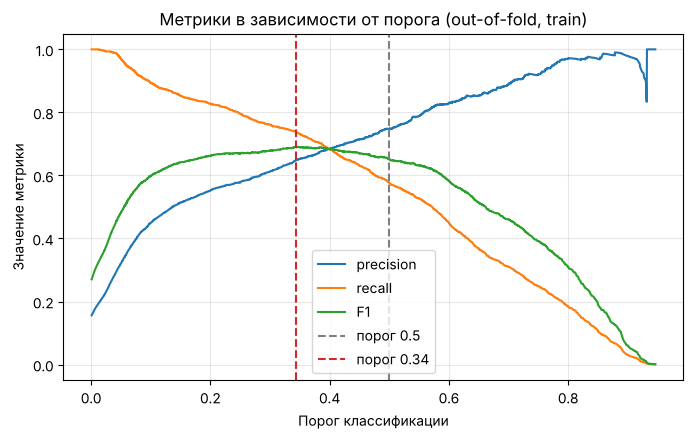

In [22]:
cv_pr = {n: s.best_score_ for n, s in searches.items()}
final_name = max(cv_pr, key=cv_pr.get)
final = clone(tuned[final_name])
print(f"Лучшая модель по CV PR-AUC: {final_name} ({cv_pr[final_name]:.4f})")

proba_oof = cross_val_predict(final, X_train, y_train, cv=cv, method="predict_proba", n_jobs=-1)[:, 1]
p, r, thr = precision_recall_curve(y_train, proba_oof)
f1s = 2 * p[:-1] * r[:-1] / (p[:-1] + r[:-1] + 1e-12)
THR = thr[f1s.argmax()]
print(f"Порог по OOF (максимум F1): {THR:.3f}, F1 на OOF = {f1s.max():.3f}")

plt.figure(figsize=(8, 4.5))
plt.plot(thr, p[:-1], label="precision")
plt.plot(thr, r[:-1], label="recall")
plt.plot(thr, f1s, label="F1")
plt.axvline(0.5, color="gray", linestyle="--", label="порог 0.5")
plt.axvline(THR, color="tab:red", linestyle="--", label=f"порог {THR:.2f}")
plt.xlabel("Порог классификации")
plt.ylabel("Значение метрики")
plt.title("Метрики в зависимости от порога (out-of-fold, train)")
plt.legend()
plt.show()

In [23]:
final.fit(X_train, y_train)
proba_test = final.predict_proba(X_test)[:, 1]
rows = []
for thr_value in [0.5, THR]:
    pred = (proba_test >= thr_value).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, pred).ravel()
    rows.append({"порог": round(thr_value, 3), "precision": precision_score(y_test, pred),
                 "recall": recall_score(y_test, pred), "F1": f1_score(y_test, pred),
                 "F1-macro": f1_score(y_test, pred, average="macro"), "accuracy": accuracy_score(y_test, pred),
                 "TP": tp, "FN": fn, "FP": fp, "TN": tn})
display(pd.DataFrame(rows).set_index("порог").round(4))
print(f"PR-AUC на тесте: {average_precision_score(y_test, proba_test):.4f}, "
      f"ROC-AUC: {roc_auc_score(y_test, proba_test):.4f}")

,precision,recall,F1,F1-macro,accuracy,TP,FN,FP,TN
порог,,,,,,,,,
0.500,0.7429,0.6204,0.6762,0.8109,0.9070,237,145,82,1977
0.343,0.6450,0.7277,0.6839,0.8104,0.8947,278,104,153,1906


PR-AUC на тесте: 0.7601, ROC-AUC: 0.9362


**Выводы по итоговой модели:**

- Лучшая модель по CV PR-AUC — случайный лес (400 деревьев, `max_depth = 8`, `max_features = 0.3`). На тесте PR-AUC 0.760 и ROC-AUC 0.936; PR-AUC на тесте близок к CV (0.756), то есть подгонки под тест нет.
- Порог, подобранный по out-of-fold предсказаниям (0.34, F1 на OOF 0.691), меняет precision на recall: на тесте recall 0.620 → 0.728, precision 0.743 → 0.645, а F1 почти не меняется (0.676 → 0.684). Пропущенных покупок становится 104 вместо 145 (из 382), ложных тревог 153 вместо 82.
- Accuracy при этом падает с 0.907 до 0.895, хотя recall вырос больше чем на 0.10: по accuracy такая замена выглядит как ухудшение. Ещё один пример, почему accuracy плохо подходит этой задаче.
- Оговорка: в тесте 382 покупки, одна ошибка меняет recall на 0.26 п. п., а выигрыш по F1 всего 0.008, то есть в пределах шума. Надёжным считаем направление (порог ниже 0.5 прибавляет recall ценой precision), но не точное значение 0.34. Выбирать порог нужно по цене ошибок, а не по максимуму F1.

## Итог по гипотезам

| № | Гипотеза | Статус | Ключевая цифра |
|---|---|---|---|
| H1 | accuracy вводит в заблуждение | подтвердилась | accuracy 0.844 у Dummy против 0.900 у леса; PR-AUC 0.156 против 0.740 |
| H2 | коррелированные признаки не нужны LogReg | подтвердилась | ΔPR-AUC = −0.0009 при std 0.02 |
| H3 | лес лучше LogReg на ≥ 0.03 | подтвердилась | PR-AUC на тесте 0.760 против 0.697 (+0.063) |
| H4 | `PageValues` — №1, плюс `ExitRates` и `ProductRelated_Duration` в топ-5 | частично | `PageValues` — 75.5% важности; `ExitRates` на 8-м месте |
| H5 | переобучение дерева при глубине > 10 | подтвердилась (раньше) | validation accuracy 0.899 → 0.860, PR-AUC 0.690 → 0.380 |
| H6 | `class_weight` резко повышает recall, роняет precision | подтвердилась | Δrecall = +0.245, Δprecision = −0.149 |
| H7 | 10 признаков не хуже всех | подтвердилась | ΔPR-AUC = −0.008 |

## Выводы

1. **Метрики.** Из-за дисбаланса accuracy почти не отличает «ничего не предсказывающую» модель (0.844) от хорошей (0.90). Работаем с PR-AUC и F1 по покупкам; решения принимаются по кросс-валидации на train, тест используется один раз.
2. **Feature engineering важнее подбора параметров для линейной модели.** `log1p` даёт +0.048 PR-AUC (на всех фолдах), а подбор `C` практически ничего (+0.002). Категориальные признаки линейной модели почти не помогли.
3. **Главный признак и главный риск.** Почти всё качество держится на `PageValues`: без него PR-AUC всех моделей падает с 0.68–0.76 до 0.32–0.38. Признак строится по истории покупок, поэтому первым делом нужно проверять, доступен ли он к моменту предсказания.
4. **Модели.** Лес выигрывает у логистической регрессии и дерева (PR-AUC 0.760 против 0.697 и 0.700 на тесте). Подобранное одиночное дерево от логистической регрессии не отличается.
5. **Переобучение.** Дерево начинает переобучаться уже после глубины 5, а PR-AUC падает быстрее, чем accuracy. Регуляризацией служит минимальный размер листа, а не только глубина.
6. **Избыточность признаков.** Удаление коррелированных признаков (H2) и отбор `SelectKBest` (H7) почти не меняют качество, потому что время на страницах дублирует число просмотренных страниц. Важность признаков у деревьев в таких парах «размазывается» (H4).
7. **Баланс классов и порог.** `class_weight` и снижение порога — два способа выбрать другой компромисс между precision и recall, а не способ получить более качественную модель. Порог 0.34 меняет на тесте precision на recall (0.743 → 0.645 и 0.620 → 0.728), а F1 почти не меняется (0.676 → 0.684).
8. **Воспроизводимость.** Все случайные процессы зафиксированы (`SEED = 42`), все преобразования стоят внутри `Pipeline`, поэтому на кросс-валидации нет утечек из validation (список коррелированных признаков для H2 определён по train без таргета и совпадает на всех фолдах).